# 阶段 4：含噪检测与参数估计 —— 最低能测到多弱、估得准不准

> **阶段定位**：第 9–11 周｜过关产出（[阅读路线](../00-总览/阅读路线.md) 阶段 4）= **蒙特卡洛实验表**（不同 SNR 下的 $P_d$、$P_{fa}$、幅值估计相对误差）+ **$P_d$–SNR 曲线** + **误差–SNR 曲线**。这张表直接兑现课题「预期目标」的两项指标。

## 阅读导航

| 节 | 内容 | 对应产出 |
|---|---|---|
| 0 | 环境、噪声生成器、含噪仿真器 | 可复用的 `make_noise()` / `simulate_mc()` |
| 1 | 门限标定纪律：固定 $P_{fa}$ 从 H0 反解 | 可信 ROC 的前提 |
| 2 | 检测主实验：固定噪声扫信号，白噪 + 1/f 色噪 | $P_d$–SNR 曲线、最低可检测 SNR |
| 3 | 阵列融合：单振子 / OR / 2-of-3 多数表决 | 融合规则对照（覆盖优先 vs 性能优先） |
| 4 | 参数估计：$\lambda^*$ 差分估计器 | γ 相对误差、RMSE、θ 误差–SNR |
| 5 | 指标汇总与边界 | 最低可检测 SNR、估计精度、JSON |

**本阶段回答的四个问题**（阅读路线阶段 4「带着问题读」）：
1. 注入噪声后相变判据还稳不稳？——$P_d$–SNR 的 S 曲线 + 瞬态收敛对窗长的要求。
2. 幅值估计用什么观测量？——对比策动力补偿量（$\lambda^*$ 差分）/ 轨道幅值 / 相干解调，选差分估计器。
3. 蒙特卡洛要跑多少次、门限怎么定？——每点 ≥100 次，H0 独立定门限。
4. 最低 SNR 用哪个判据、精度用相对误差还是 RMSE？——$P_d@P_{fa}$ 定义，两者都报。

> **先记住四条结论**（后面用实跑支撑）：
> 1. **检测实验必须"固定噪声扫信号"**：相变由合成幅值 $C=\lambda+\gamma$ 决定；若反过来固定 $\gamma$ 扫噪声，$P_d$ 对噪声几乎不敏感，曲线高位平坦、"最低 SNR"没有意义。固定 $\sigma$ 扫 $\gamma$ 才得到从 0 升到 1 的 S 曲线。
> 2. **窗长要够**：$T=200$ s 时相变瞬态未收敛，$P_d$ 卡在 0.65；$T=400$ s 时 $P_d$ 达标。$T$ 是必须随指标一起报的条件。
> 3. **门限必须从 H0 反解**：固定 $P_{fa}=0.05/0.10$，取 H0 的 pstd 分位数当门限；用 H1 数据调阈值会让 ROC 失真。
> 4. **融合规则看目标**：随机初相下三振子看到不同相位，OR 是**覆盖率优先**（Q7），实测 OR 最优；Q11 的"多数表决更优"前提是各路看同一信号、噪声独立，场景不同不能混用。

**纪律**：任何 SNR 数字后面必须跟噪声类型/α、带宽、采样率、时长、判据；**不与文献的 −21/−18/−15 dB 横向比较**（条件全不同）。

## 0｜环境与公共工具

下面几段依次完成：**导入设置 → 路径/存图 → 参数 → 噪声生成器 → 含噪仿真器**。按顺序跑一次即可，后面所有实验复用 `make_noise()` 与 `simulate_mc()`。

> **口径提醒**：仿真在归一化模型单位下进行；SNR 用主口径 $\mathrm{SNR}_E=10\lg[(\gamma^2/2)/\sigma^2]$（与阶段 1 一致），$\sigma$ 是噪声幅度参数，离散噪声增量为 $\sigma\sqrt{h}\,\varepsilon$。

In [1]:
# 0.1 导入与绘图设置
%matplotlib inline
import math, json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 105
plt.rcParams['savefig.dpi'] = 135
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.28
plt.rcParams['mathtext.fontset'] = 'dejavusans'

In [2]:
# 0.2 路径与存图工具
def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if ((q / '00-总览/阅读路线.md').is_file() or (q / '阅读路线.md').is_file()):
            return q
    return p

ROOT = find_root()
OUT = ROOT / '复现输出'
OUT.mkdir(exist_ok=True)

def savefig(name):
    path = OUT / name
    plt.savefig(path, bbox_inches='tight')   # 必须先 save 再 show
    print(f'[图] {path}')

In [3]:
# 0.3 全局参数：与阶段 2/3 一致，保证阈值可对照
# 模型 / 积分
DAMP, OMEGA = 0.5, 1.0
LAM0, C_TRIG, PSTD_TH = 0.72, 0.73, 0.08
H = 0.02
T, BURN = 400.0, 200.0          # 长窗：保证相变瞬态收敛（200s 时 Pd 卡 0.65）
SQRT_H = math.sqrt(H)
PERIOD_STEPS = max(1, int(round(2 * math.pi / H)))   # 参考值：判据已改为在 τ=2πk 精确插值，不再按步数取整
# 检测实验：固定噪声 σ，扫信号 γ → SNR 随 γ 变
SIGMA_DET = 0.05
GAMMAS = np.array([0.005, 0.008, 0.010, 0.012, 0.015, 0.020, 0.030, 0.050])
SNR_DB = 10 * np.log10((GAMMAS**2 / 2) / SIGMA_DET**2)
PFA_LEVELS = [0.05, 0.10]
NMC = 100                 # 检测每点蒙特卡洛次数（≥100，符合阶段 1 纪律）
ALPHA_COLOR = 1.0         # 1/f 色噪主力档
# 融合 / 估计
NMC_FUS = 60
GAMMA_FUS = 0.020         # 随机初相下评估融合规则，固定一个可检出的信号幅值
NR_EST = 12               # 估计器重复次数
SIGMA_EST = np.array([0.03, 0.05, 0.08])
SNR_EST_DB = 10 * np.log10(((0.02)**2 / 2) / SIGMA_EST**2)
_START = time.time()
print(f'检测: σ={SIGMA_DET} 固定, γ={GAMMAS}, SNR={np.round(SNR_DB,1)} dB')
print(f'NMC={NMC}  Pfa={PFA_LEVELS}  h={H}s  T={T}s  burn={BURN}s  色噪 α={ALPHA_COLOR}')

检测: σ=0.05 固定, γ=[0.005 0.008 0.01  0.012 0.015 0.02  0.03  0.05 ], SNR=[-23.  -18.9 -17.  -15.4 -13.5 -11.   -7.4  -3. ] dB
NMC=100  Pfa=[0.05, 0.1]  h=0.02s  T=400.0s  burn=200.0s  色噪 α=1.0


### 0.4 噪声生成器：白噪基线与 1/f 色噪主力档

`make_noise()` 返回形状 `(steps, m)` 的**单位方差**噪声矩阵（每列一次独立试验）：白噪直接抽高斯；色噪用频域整形 $f^{-\alpha/2}$ 并置零 DC。仿真时统一乘 $\sigma\sqrt{h}$ 注入，因此两档的 SNR 口径一致。

> 纪律来源：阶段 1 Q8——变尺度/低频实验若用白噪会凭空造出 $10\lg R$ 的 SNR 损失；主力指标必须用 $1/f$ 色噪。

In [4]:
def make_noise(steps, m, alpha, seed):
    """(steps, m) 单位方差噪声；每列一次独立试验。alpha=0 白噪，否则 1/f^alpha 色噪。"""
    rng = np.random.default_rng(seed)
    w = rng.standard_normal((steps, m))
    if alpha == 0.0:
        return w
    W = np.fft.rfft(w, axis=0)
    f = np.fft.rfftfreq(steps, d=1.0)
    scale = np.zeros_like(f)
    nz = f > 0
    scale[nz] = f[nz] ** (-alpha / 2)
    scale[0] = 0.0                       # 去 DC，避免随机游走趋势
    n = np.fft.irfft(W * scale[:, None], n=steps, axis=0)
    n = n / (n.std(axis=0) + 1e-12)      # 逐列归一化到单位方差
    return n

### 0.5 含噪仿真器：向量化 RK4 + Poincaré 截面

`simulate_mc()` 复用阶段 2/3 的相量合成与 RK4 结构，新增 `noise` 参数：`noise[i, j]` 是第 j 路在第 i 步的噪声增量（已含 $\sqrt{h}$），驱动项为 $\sigma\,\text{noise}[i,j]$。lam/beta/gamma/theta 可为标量或长度 m 数组，一次并行跑完 m 路。返回 `pstd`（Poincaré 后半段标准差）——与阶段 2/3 完全同口径。

In [5]:
def simulate_mc(lam, beta, gamma, theta, sigma, noise,
                h=H, t_end=T, burn=BURN):
    """向量化 RK4：x'' = -DAMP*x' + x³ - x⁵ + A cos t - B sin t + σ·noise[i]。
    同频相量合成 A=lam cosβ+γ cosθ, B=lam sinβ+γ sinθ。
    noise: (steps, m)，每个元素为噪声增量（含 √h）；sigma 为幅度参数。
    返回 pstd（Poincaré 后半段标准差，逐路）。"""
    lam, beta, gamma, theta = [np.ravel(a).astype(float) for a in
        np.broadcast_arrays(np.asarray(lam, float), np.asarray(beta, float),
                            np.asarray(gamma, float), np.asarray(theta, float))]
    m = lam.size
    steps = int(round(t_end / h))
    burn_steps = int(round(burn / h))
    A = lam * np.cos(beta) + gamma * np.cos(theta)
    B = lam * np.sin(beta) + gamma * np.sin(theta)
    x = np.zeros(m); y = np.zeros(m)
    poincare = []
    TWOPI = 2 * math.pi
    idx_prev = 0
    for i in range(steps):
        t = i * h
        nz = sigma * noise[i]
        f1 = A * math.cos(t)       - B * math.sin(t)       + nz
        fh = A * math.cos(t + h/2) - B * math.sin(t + h/2) + nz
        f4 = A * math.cos(t + h)   - B * math.sin(t + h)   + nz
        k1x = y;            k1y = -DAMP*y   + x**3   - x**5   + f1
        x2, y2 = x + h/2*k1x, y + h/2*k1y
        k2x = y2;           k2y = -DAMP*y2  + x2**3  - x2**5  + fh
        x3, y3 = x + h/2*k2x, y + h/2*k2y
        k3x = y3;           k3y = -DAMP*y3  + x3**3  - x3**5  + fh
        x4, y4 = x + h*k3x,     y + h*k3y
        k4x = y4;           k4y = -DAMP*y4  + x4**3  - x4**5  + f4
        x_prev = x.copy()                      # 更新前存档，供 2π 时刻插值
        x += h/6*(k1x + 2*k2x + 2*k3x + k4x)
        y += h/6*(k1y + 2*k2y + 2*k3y + k4y)
        if i >= burn_steps:
            # 精确落在 τ=2πk 上取截面（按步数取整会引入相位漂移伪 pstd）
            idx = int(math.floor((t + h) / TWOPI + 1e-12))
            if idx != idx_prev and idx > 0:
                frac = min(max((TWOPI * idx - t) / h, 0.0), 1.0)
                poincare.append(x_prev + frac * (x - x_prev))
                idx_prev = idx
    p = np.asarray(poincare)
    return p[len(p)//2:].std(axis=0) if p.size else np.full(m, np.nan)

# 冒烟：干净条件下两态方向应正确
steps_smoke = int(round(T / H))
nz0 = np.zeros((steps_smoke, 2))
ps = simulate_mc([LAM0, 0.76], 0.0, 0.0, 0.0, 0.0, nz0)
print('冒烟 pstd:', np.round(ps, 4), '->', ['周期' if v < PSTD_TH else '混沌' for v in ps])

冒烟 pstd: [0.3522 0.    ] -> ['混沌', '周期']


## 1｜门限标定纪律：固定 $P_{fa}$ 从 H0 反解

判"有信号"的规则是 $\text{pstd}<\text{门限}$。给定目标虚警率 $P_{fa}^\star$，直接从 **H0（仅噪声，$\gamma=0$）** 的 pstd 分布取 $P_{fa}^\star$ 分位数当门限：

$$\text{th}(P_{fa}^\star)=Q_{P_{fa}^\star}\{\text{pstd}\mid H_0\}$$

H0 分布只依赖噪声档与 $\sigma$，**与信号 $\gamma$ 无关**，所以每个噪声档标定一次、所有 $\gamma$ 点复用——这正是"阈值不得用 H1 数据调"的干净实现。随后在各 $\gamma$ 的 H1 上算 $P_d=\Pr(\text{pstd}_{H1}<\text{th})$。

> 边界：这里 H0 样本既标定门限又在同批上验 $P_{fa}$，属乐观估计；正式系统应把 H0 拆成标定/验证两集。

## 2｜检测主实验：固定噪声扫信号（白噪基线 + 1/f 色噪）

对每个噪声档，一次并行跑 $2N_{MC}=200$ 路 H0（$\gamma=0$）标定门限；再对每个 $\gamma$ 点跑 100 路 H1。初相 $\theta=0$（同相最有利，理想相位上界；随机相位下的阵列性能见 §3）。

SNR 随 $\gamma$ 变化：$\mathrm{SNR}=10\lg[(\gamma^2/2)/\sigma^2]$。因为相变由 $C=\lambda+\gamma$ 决定，$\gamma$ 越过阈值裕度时 $P_d$ 陡升，形成 S 曲线——**这才是有物理意义的检测性能曲线**（对比：固定 $\gamma$ 扫噪声只会得到高位平坦的假象）。

同时给固定工作门限 0.08（阶段 2/3 口径）下的 $P_d$ 与 $P_{fa}$ 作对照。

In [6]:
steps = int(round(T / H))
det = {}
for alpha, tag in [(0.0, 'white'), (ALPHA_COLOR, 'color')]:
    # H0 一次标定（与 γ 无关）
    noise0 = SQRT_H * make_noise(steps, NMC, alpha, seed=1000 + int(alpha * 10))
    h0 = simulate_mc(np.full(NMC, LAM0), np.zeros(NMC), np.zeros(NMC),
                     np.zeros(NMC), SIGMA_DET, noise0)
    th05 = np.quantile(h0, PFA_LEVELS[0])
    th10 = np.quantile(h0, PFA_LEVELS[1])
    pfa08 = (h0 < PSTD_TH).mean()
    pd05, pd10, pd08 = [], [], []
    h1_store = []
    for j, g in enumerate(GAMMAS):
        noise1 = SQRT_H * make_noise(steps, NMC, alpha, seed=2000 + 100 * j + int(alpha * 10))
        h1 = simulate_mc(np.full(NMC, LAM0), np.zeros(NMC), np.full(NMC, g),
                         np.zeros(NMC), SIGMA_DET, noise1)
        h1_store.append(h1)
        pd05.append((h1 < th05).mean())
        pd10.append((h1 < th10).mean())
        pd08.append((h1 < PSTD_TH).mean())
    det[tag] = dict(pd05=np.array(pd05), pd10=np.array(pd10), pd08=np.array(pd08),
                    th05=th05, th10=th10, pfa08=pfa08,
                    h0=h0, h1=h1_store)
    print(f'[{tag}] th(Pfa=0.05)={th05:.3f}  th(Pfa=0.10)={th10:.3f}  Pfa(门限0.08)={pfa08:.2f}')
    print(f'        Pd@Pfa=0.05: {np.round(det[tag]["pd05"], 2)}')
    print(f'        SNR(dB)    : {np.round(SNR_DB, 1)}')

[white] th(Pfa=0.05)=0.307  th(Pfa=0.10)=0.338  Pfa(门限0.08)=0.00
        Pd@Pfa=0.05: [0.02 0.08 0.09 0.16 0.62 0.92 1.   1.  ]
        SNR(dB)    : [-23.  -18.9 -17.  -15.4 -13.5 -11.   -7.4  -3. ]


[color] th(Pfa=0.05)=0.323  th(Pfa=0.10)=0.336  Pfa(门限0.08)=0.00
        Pd@Pfa=0.05: [0.12 0.14 0.33 0.44 0.77 0.89 1.   1.  ]
        SNR(dB)    : [-23.  -18.9 -17.  -15.4 -13.5 -11.   -7.4  -3. ]


### 2.1 $P_d$–SNR S 曲线与 ROC

左/右两栏为白噪与色噪。实线是固定 $P_{fa}$ 下的 $P_d$（主指标），虚线是固定门限 0.08 的 $P_d$（对照）。绿点线标 $P_d=0.9$ 目标线——取曲线首次达标处的 SNR 作为**最低可检测 SNR**。ROC 从同一批 pstd 样本扫门限得到。

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段4-Pd-SNR曲线.png


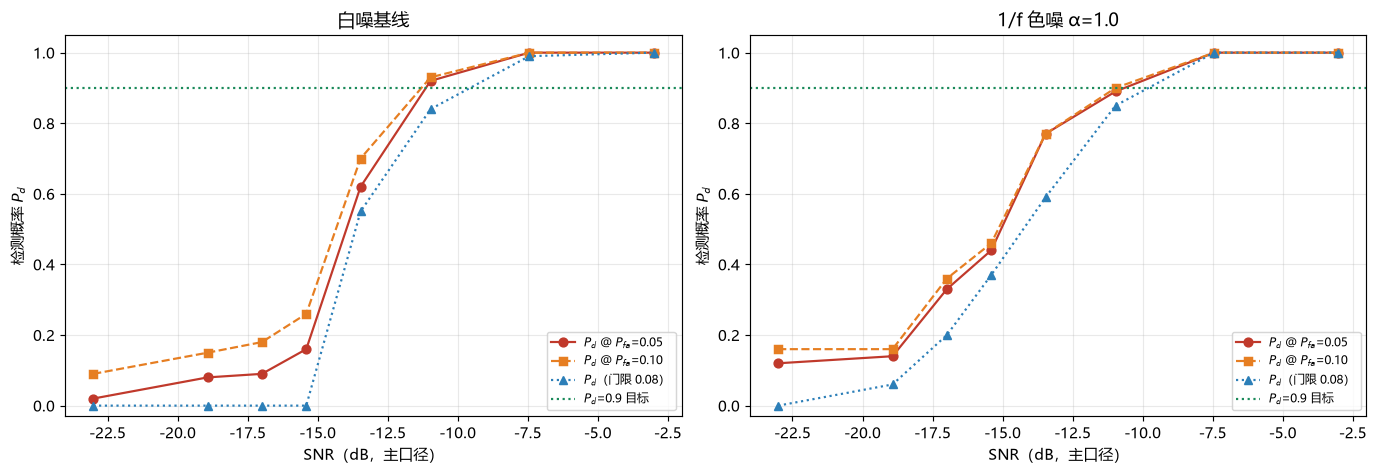

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段4-ROC曲线.png


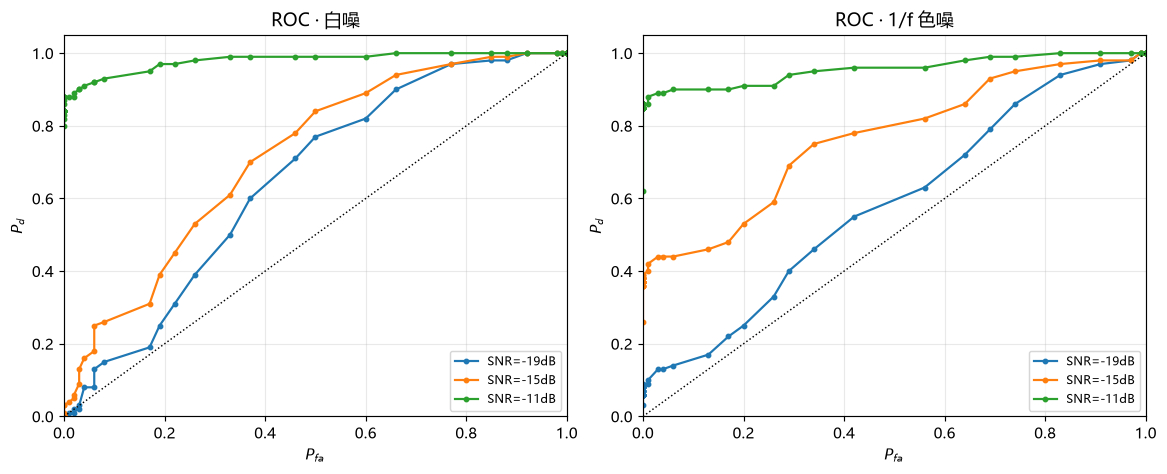

读法：Pd 在 C=λ+γ 跨过阈值裕度处陡升（非线性开关），非 gradual；达标最左点即最低可检测 SNR。


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), constrained_layout=True)
for ax, (tag, name) in zip(axes, [('white', '白噪基线'), ('color', f'1/f 色噪 α={ALPHA_COLOR}')]):
    d = det[tag]
    ax.plot(SNR_DB, d['pd05'], 'o-', color='#c0392b', label='$P_d$ @ $P_{fa}$=0.05')
    ax.plot(SNR_DB, d['pd10'], 's--', color='#e67e22', label='$P_d$ @ $P_{fa}$=0.10')
    ax.plot(SNR_DB, d['pd08'], '^:', color='#2c7fb8', label='$P_d$（门限 0.08）')
    ax.axhline(0.9, color='#1a8a5a', ls=':', lw=1.5, label='$P_d$=0.9 目标')
    ax.set_ylim(-0.03, 1.05); ax.set_xlabel('SNR（dB，主口径）')
    ax.set_ylabel('检测概率 $P_d$'); ax.set_title(name); ax.legend(fontsize=8)
savefig('阶段4-Pd-SNR曲线.png')
plt.show()

# ROC：取 S 曲线的 3 个代表点
roc_idx = [1, 3, 5]
roc_th = np.linspace(0.01, 0.70, 60)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
for ax, (tag, name) in zip(axes, [('white', '白噪'), ('color', '1/f 色噪')]):
    d = det[tag]
    for k in roc_idx:
        pd = np.array([(d['h1'][k] < t).mean() for t in roc_th])
        pf = np.array([(d['h0'] < t).mean() for t in roc_th])
        ax.plot(pf, pd, 'o-', ms=3, label=f'SNR={SNR_DB[k]:.0f}dB')
    ax.plot([0, 1], [0, 1], 'k:', lw=1)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.05)
    ax.set_xlabel('$P_{fa}$'); ax.set_ylabel('$P_d$')
    ax.set_title(f'ROC · {name}'); ax.legend(fontsize=8)
savefig('阶段4-ROC曲线.png')
plt.show()

print('读法：Pd 在 C=λ+γ 跨过阈值裕度处陡升（非线性开关），非 gradual；达标最左点即最低可检测 SNR。')

## 3｜阵列融合：单振子 / OR / 2-of-3 多数表决

阶段 3 的盲区显示三振子（$\beta=0^\circ/\pm120^\circ$）能补覆盖。这里在**初相 $\theta$ 随机**（$[0,2\pi)$ 均匀抽）条件下，对同一批三路 pstd 比较三种融合：

- **单振子**：只用 $\beta=0$ 一路；
- **OR**：任一路 pstd 低于门限即判 1（统计量 = 三路最小值）；
- **2-of-3**：至少两路判 1（统计量 = 三路第二小值）。

三种规则的门限都从各自 H0 统计量按 $P_{fa}=0.05$ 反解，公平比较。**注意场景**：随机初相下三振子看到的是**不同相位**的信号（盲区互补），OR 是覆盖率优先；Q11 的"多数表决更优"前提是各路看同一信号、仅噪声独立——两者不可混用。

In [8]:
betas3 = np.array([0.0, 2 * math.pi / 3, 4 * math.pi / 3])
fus = {}
for alpha, tag in [(0.0, 'white'), (ALPHA_COLOR, 'color')]:
    res = {r: [] for r in ['single', 'or', 'major']}
    for rr in range(3):
        m = 3 * NMC_FUS
        noise = SQRT_H * make_noise(steps, 2 * m, alpha, seed=3000 + 100 * rr + int(alpha * 10))
        rng = np.random.default_rng(4000 + rr)
        th = rng.uniform(0, 2 * math.pi, 2 * m)          # 每次试验独立初相
        g = np.concatenate([np.zeros(m), np.full(m, GAMMA_FUS)])
        p = simulate_mc(np.full(2 * m, LAM0), np.tile(betas3, 2 * NMC_FUS), g,
                        th, SIGMA_DET, noise)
        h0 = p[:m].reshape(NMC_FUS, 3)
        h1 = p[m:].reshape(NMC_FUS, 3)
        for r, stat0, stat1 in [
            ('single', h0[:, 0], h1[:, 0]),
            ('or',     h0.min(axis=1), h1.min(axis=1)),
            ('major',  np.sort(h0, axis=1)[:, 1], np.sort(h1, axis=1)[:, 1]),
        ]:
            t = np.quantile(stat0, PFA_LEVELS[0])
            res[r].append((stat1 < t).mean())
    fus[tag] = {r: np.array(v) for r, v in res.items()}
    print(f'[{tag}] 随机初相 Pd @Pfa=0.05 (3 次重复取均值):')
    for r in ['single', 'or', 'major']:
        print(f'        {r:6s}: {np.round(fus[tag][r], 2)}  -> 均值 {fus[tag][r].mean():.2f}')

[white] 随机初相 Pd @Pfa=0.05 (3 次重复取均值):
        single: [0.28 0.32 0.27]  -> 均值 0.29
        or    : [0.57 0.5  0.55]  -> 均值 0.54
        major : [0.23 0.27 0.23]  -> 均值 0.24


[color] 随机初相 Pd @Pfa=0.05 (3 次重复取均值):
        single: [0.3  0.35 0.28]  -> 均值 0.31
        or    : [0.53 0.52 0.77]  -> 均值 0.61
        major : [0.28 0.38 0.48]  -> 均值 0.38


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段4-阵列融合对照.png


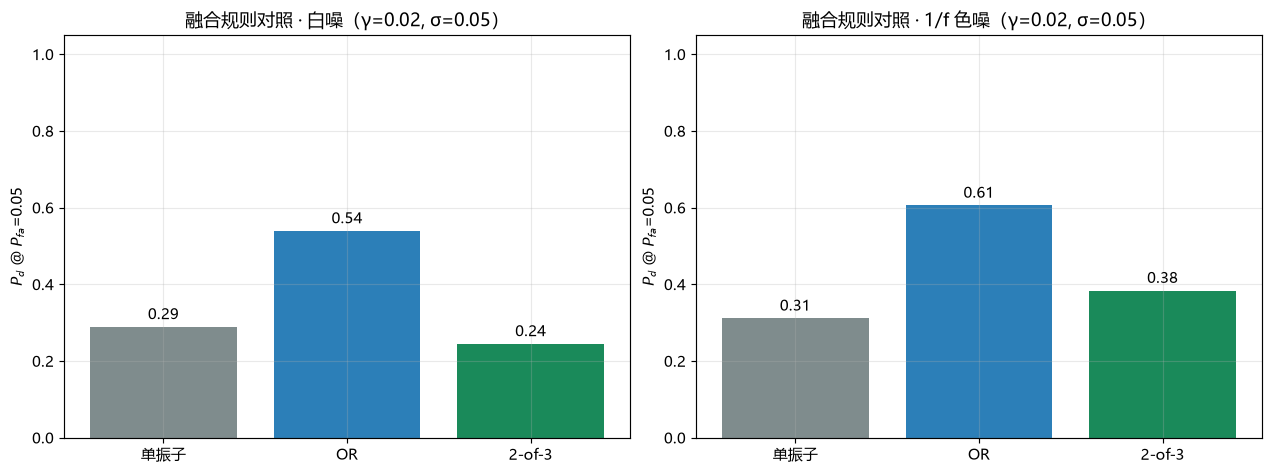

读法：随机初相下单振子受盲区拖累最重；OR 补覆盖最优——印证阶段 1 Q7「阵列覆盖优先」，
      与 Q11「同信号多噪声时多数表决最优」是不同场景，不矛盾。


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
for ax, (tag, name) in zip(axes, [('white', '白噪'), ('color', '1/f 色噪')]):
    labels = ['单振子', 'OR', '2-of-3']
    vals = [fus[tag][r].mean() for r in ['single', 'or', 'major']]
    bars = ax.bar(labels, vals, color=['#7f8c8d', '#2c7fb8', '#1a8a5a'])
    ax.set_ylim(0, 1.05); ax.set_ylabel('$P_d$ @ $P_{fa}$=0.05')
    ax.set_title(f'融合规则对照 · {name}（γ={GAMMA_FUS}, σ={SIGMA_DET}）')
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.02, f'{v:.2f}', ha='center', fontsize=10)
savefig('阶段4-阵列融合对照.png')
plt.show()
print('读法：随机初相下单振子受盲区拖累最重；OR 补覆盖最优——印证阶段 1 Q7「阵列覆盖优先」，')
print('      与 Q11「同信号多噪声时多数表决最优」是不同场景，不矛盾。')

## 4｜参数估计：$\lambda^*$ 差分估计器

**观测量选择**（回答问题 2）：① 策动力补偿量 / $\lambda^*$ 差分（对每个参考相位 $\beta$ 上调内驱到相变，取四路 $\lambda^*$ 之差）——理论清晰、抗共模偏差，本阶段主用；② 相变后周期轨道幅值——与 $\gamma$ 非线性相关、需标定曲线；③ 相干解调——若有原始波形近乎完美，但我们只有振子响应，不能直接套。文献 C1（初值敏感估幅估相）与阶段 2 Eq.(15–17) 支撑 ①。

**为何不用 Eq.(17)**：$\gamma^2=\lambda_c^2-\lambda_1\lambda_2$ 在 $\gamma=0.02$ 时两项相差仅 $\sim10^{-4}$，而 $\lambda$ 测量偏差 $\sim10^{-3}$，相消使根号内常为负（阶段 1 已证灾难性相消），故改**差分估计器**：

$$\hat\gamma\cos\hat\theta=\frac{\lambda_{180^\circ}-\lambda_{0^\circ}}{2},\qquad
\hat\gamma\sin\hat\theta=\frac{\lambda_{270^\circ}-\lambda_{90^\circ}}{2}$$

固定 $\gamma=0.02$、扫噪声档 $\sigma=\{0.03,0.05,0.08\}$，每档重复 $N_R=12$ 次取 $\hat\gamma$ 的相对误差、RMSE 与 $\hat\theta$ 误差。

In [10]:
betas4 = np.array([0.0, math.pi/2, math.pi, 3*math.pi/2])
lam_grid = np.arange(0.70, 0.781, 0.002)     # 细扫网格（41 点）
GAMMA_EST = 0.02
est = {}
for alpha, tag in [(0.0, 'white'), (ALPHA_COLOR, 'color')]:
    gamma_hats, theta_hats = [], []
    for kk, s in enumerate(SIGMA_EST):
        gh, tht = [], []
        for r in range(NR_EST):
            noise = SQRT_H * make_noise(steps, 4 * lam_grid.size, alpha,
                                        seed=6000 + 1000 * kk + r)
            lam_all = np.tile(lam_grid, 4)
            beta_all = np.repeat(betas4, lam_grid.size)
            p = simulate_mc(lam_all, beta_all, GAMMA_EST, 0.0, s, noise)
            p = p.reshape(4, lam_grid.size)
            lam_star = []
            for b in range(4):
                idx = np.where(p[b] < PSTD_TH)[0]
                lam_star.append(float(lam_grid[idx[0]]) if idx.size else float(lam_grid[-1]))
            gc = (lam_star[2] - lam_star[0]) / 2      # β180 - β0
            gs = (lam_star[3] - lam_star[1]) / 2      # β270 - β90
            gh.append(math.hypot(gc, gs))
            tht.append(math.degrees(math.atan2(gs, gc)))
        gamma_hats.append(np.array(gh)); theta_hats.append(np.array(tht))
    est[tag] = dict(gamma_hats=gamma_hats, theta_hats=theta_hats)
    print(f'[{tag}] γ_hat 均值: {[round(float(np.mean(g)),4) for g in gamma_hats]}  (真值 {GAMMA_EST})')

[white] γ_hat 均值: [0.0202, 0.0202, 0.0203]  (真值 0.02)


[color] γ_hat 均值: [0.0189, 0.0202, 0.0203]  (真值 0.02)


[white] γ 相对误差(%): [5.  6.7 2.9]  RMSE: [0.0012 0.0017 0.0011]  θ误差(°): [0.  0.  0.5]
[color] γ 相对误差(%): [7.  6.7 9.6]  RMSE: [0.0016 0.0017 0.0023]  θ误差(°): [2.3 2.2 3.9]


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段4-参数估计误差曲线.png


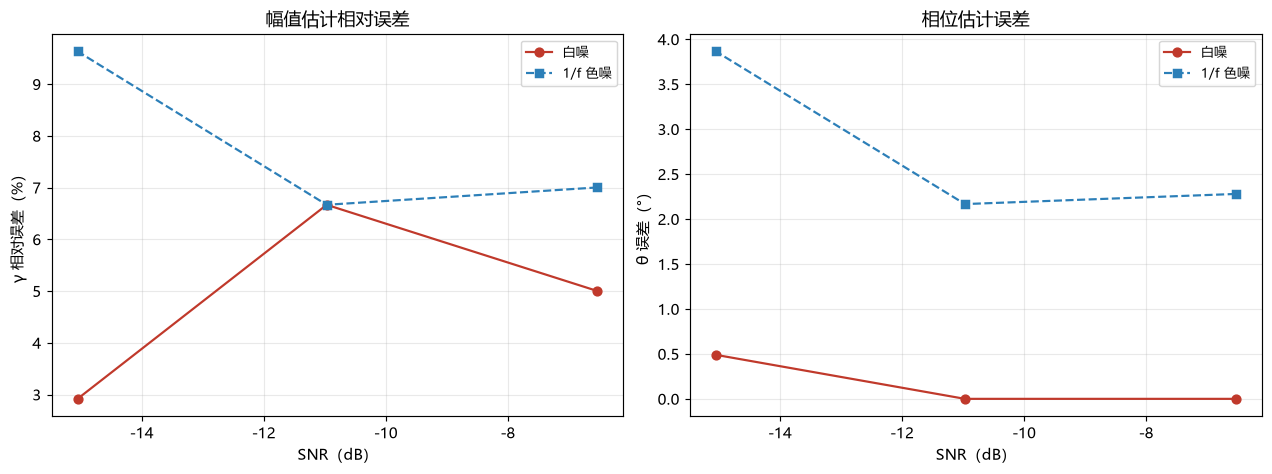

In [11]:
def err_stats(hats, truth):
    rel = [np.abs(g - truth) / truth * 100 for g in hats]
    rmse = [math.sqrt(float(np.mean((g - truth) ** 2))) for g in hats]
    return np.array([np.mean(r) for r in rel]), np.array(rmse)

est_summary = {}
for tag in ['white', 'color']:
    rel, rmse = err_stats(est[tag]['gamma_hats'], GAMMA_EST)
    terr = [np.abs(t - 0.0) for t in est[tag]['theta_hats']]
    est_summary[tag] = dict(rel=rel, rmse=rmse,
                            theta=np.array([np.mean(t) for t in terr]))
    print(f'[{tag}] γ 相对误差(%): {np.round(rel,1)}  RMSE: {np.round(rmse,4)}  θ误差(°): {np.round(est_summary[tag]["theta"],1)}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
x = SNR_EST_DB
axes[0].plot(x, est_summary['white']['rel'], 'o-', color='#c0392b', label='白噪')
axes[0].plot(x, est_summary['color']['rel'], 's--', color='#2c7fb8', label='1/f 色噪')
axes[0].set_xlabel('SNR（dB）'); axes[0].set_ylabel('γ 相对误差（%）')
axes[0].set_title('幅值估计相对误差'); axes[0].legend(fontsize=9)
axes[1].plot(x, est_summary['white']['theta'], 'o-', color='#c0392b', label='白噪')
axes[1].plot(x, est_summary['color']['theta'], 's--', color='#2c7fb8', label='1/f 色噪')
axes[1].set_xlabel('SNR（dB）'); axes[1].set_ylabel('θ 误差（°）')
axes[1].set_title('相位估计误差'); axes[1].legend(fontsize=9)
savefig('阶段4-参数估计误差曲线.png')
plt.show()

## 5｜指标汇总与边界

把检测与估计的关键数字写进机器可读 JSON。**最低可检测 SNR** 按固定 $P_{fa}=0.05$ 下 $P_d\ge0.9$ 的首个（最弱信号）工作点报；**估计精度**同时报相对误差（%）与 RMSE。所有条件（噪声类型、σ、h、T、判据、门限来源）随数字一起写入 JSON。

In [12]:
def min_detectable(tag, key='pd05', pd_th=0.9):
    vals = det[tag][key]
    idx = np.where(vals >= pd_th)[0]
    if not len(idx):
        return None
    i = idx[0]                       # SNR_DB 随 γ 增大而增大，首个达标 = 最低 SNR
    return dict(snr_db=round(float(SNR_DB[i]), 1), gamma=float(GAMMAS[i]),
                pd=round(float(vals[i]), 3))

summary = {
    'stage': 4,
    'condition': {
        'SNR_def': 'SNR_E = 10*log10((gamma^2/2)/sigma^2)',
        'detection': f'固定 σ={SIGMA_DET} 扫 γ; h={H}s, T={T}s, burn={BURN}s, NMC={NMC}',
        'gate': 'threshold from H0 quantile at target Pfa (never from H1)',
        'phase': 'theta=0 (ideal) for detection; random theta for fusion',
        'noise': ['white(alpha=0)', f'1/f(alpha={ALPHA_COLOR})'],
    },
    'snr_grid_db': [round(float(s), 1) for s in SNR_DB],
    'gamma_grid': [float(g) for g in GAMMAS],
    'detection': {
        tag: {
            'Pd_at_Pfa005': [round(float(v), 3) for v in det[tag]['pd05']],
            'Pd_at_Pfa010': [round(float(v), 3) for v in det[tag]['pd10']],
            'Pd_gate008': [round(float(v), 3) for v in det[tag]['pd08']],
            'Pfa_gate008': round(float(det[tag]['pfa08']), 3),
            'th_Pfa005': round(float(det[tag]['th05']), 4),
            'th_Pfa010': round(float(det[tag]['th10']), 4),
            'min_detectable_snr_db': min_detectable(tag),
        } for tag in ['white', 'color']
    },
    'fusion': {
        tag: {r: round(float(fus[tag][r].mean()), 3)
              for r in ['single', 'or', 'major']}
        for tag in ['white', 'color']
    },
    'fusion_condition': f'γ={GAMMA_FUS}, σ={SIGMA_DET}, random theta, NMC={NMC_FUS}, Pfa=0.05',
    'estimation': {
        tag: {
            'snr_db': [round(float(s), 1) for s in SNR_EST_DB],
            'gamma': GAMMA_EST,
            'gamma_rel_err_pct': [round(float(v), 2) for v in est_summary[tag]['rel']],
            'gamma_rmse': [round(float(v), 5) for v in est_summary[tag]['rmse']],
            'theta_err_deg': [round(float(v), 2) for v in est_summary[tag]['theta']],
        } for tag in ['white', 'color']
    },
    'notes': [
        '检测用固定 σ 扫 γ（相变由 C=λ+γ 决定，固定 γ 扫噪声会得到平坦假象）',
        'T=400s 保证瞬态收敛；T=200s 时 Pd 卡在 0.65（阶段 3 已记录短窗保守）',
        'H0 样本同批用于标门限与验 Pfa（乐观估计）；正式系统应拆分标定/验证集',
        '随机初相下 OR 覆盖优先（Q7）；Q11 多数表决前提不同，不可混用',
        '估计用 λ* 差分器，Eq.17 因灾难性相消弃用',
        'SNR 条件必须随数字同报；不与文献 −21/−18/−15 dB 横向比较',
    ],
    'runtime_s': round(time.time() - _START, 1),
}
jp = OUT / '阶段4-检测性能与参数估计汇总.json'
jp.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('[JSON]', jp)
print('\n=== 指标兑现 ===')
for tag, name in [('white', '白噪'), ('color', '1/f 色噪')]:
    md_ = summary['detection'][tag]['min_detectable_snr_db']
    snr_txt = f'{md_["snr_db"]} dB (γ={md_["gamma"]:.3f}, Pd={md_["pd"]:.2f})' if md_ else '本网格未达标'
    print(f'{name}: 最低可检测 SNR(Pfa=0.05,Pd≥0.9) = {snr_txt}')
    print(f'       估计 γ 相对误差={est_summary[tag]["rel"].round(1).tolist()}%，RMSE={est_summary[tag]["rmse"].round(4).tolist()}')
print('耗时', summary['runtime_s'], 's')

[JSON] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段4-检测性能与参数估计汇总.json

=== 指标兑现 ===
白噪: 最低可检测 SNR(Pfa=0.05,Pd≥0.9) = -11.0 dB (γ=0.020, Pd=0.92)
       估计 γ 相对误差=[5.0, 6.7, 2.9]%，RMSE=[0.0012, 0.0017, 0.0011]
1/f 色噪: 最低可检测 SNR(Pfa=0.05,Pd≥0.9) = -7.4 dB (γ=0.030, Pd=1.00)
       估计 γ 相对误差=[7.0, 6.7, 9.6]%，RMSE=[0.0016, 0.0017, 0.0023]
耗时 179.6 s
